# Multilabel: the best model depends on the operator

Which model is best? On a multilabel benchmark the answer changes with how the measure is
aggregated: pooled over all labels (micro), per label then averaged (macro), or per example
then averaged (exemplar). This notebook compares three classifiers on the *yeast* benchmark
under every combination of six measures and three operators, and shows the ranking flip.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.multioutput import MultiOutputClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from aggmetrics import IndicatorMatrix, diagnose, fold_aggregate

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## Data and models

*yeast* (Elisseeff and Weston): 2417 genes, 103 features, 14 labels. The labels are strongly
imbalanced: prevalence ranges from 1.4 % to 75 %. The data are in the repository
(`examples/data/yeast.npz`, with its source and citation in the README next to it) and are
fetched from GitHub when the notebook runs elsewhere, as in Colab. Three binary-relevance
classifiers are compared with 5-fold cross-validation.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/yeast.npz"
local = Path("../data/yeast.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    X, Y = z["X"], z["Y"].astype(int)
print("examples, features, labels:", X.shape[0], X.shape[1], Y.shape[1])
print("label prevalence, min to max:", Y.mean(axis=0).min().round(3), "to", Y.mean(axis=0).max().round(3))

examples, features, labels: 2417 103 14
label prevalence, min to max: 0.014 to 0.751


In [4]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
    "kNN (k=10)": make_pipeline(StandardScaler(), KNeighborsClassifier(10)),
}

# one IndicatorMatrix per test fold and model
cv = KFold(5, shuffle=True, random_state=0)
folds = {name: [] for name in models}
for train, test in cv.split(X):
    for name, model in models.items():
        fitted = MultiOutputClassifier(model).fit(X[train], Y[train])
        folds[name].append(IndicatorMatrix(Y[test], fitted.predict(X[test]), task="multilabel"))
print("fold sizes:", [im.n for im in folds["Random forest"]])

fold sizes: [484, 484, 483, 483, 483]


The folds have different sizes (2417 is not a multiple of 5). `fold_aggregate` with
`pooling="pooled"` concatenates the five test folds' predictions before computing the measure,
which is the right way to evaluate a non-linear measure across folds.

## The measure × operator grid

Six measures, three operators, all from one call path.

In [5]:
measures = ["precision", "recall", "f1", "jaccard", "balanced_accuracy", "mcc"]
operators = ["micro", "macro", "exemplar"]

grid = pd.DataFrame({
    name: {f"{op}-{ms}": fold_aggregate(ims, ms, op, pooling="pooled")
           for op in operators for ms in measures}
    for name, ims in folds.items()
})
grid.round(3)

,Logistic regression,Random forest,kNN (k=10)
micro-precision,0.683,0.745,0.727
micro-recall,0.577,0.560,0.555
micro-f1,0.625,0.639,0.630
micro-jaccard,0.455,0.470,0.459
micro-balanced_accuracy,0.730,0.738,0.732
micro-mcc,0.485,0.523,0.507
macro-precision,0.511,0.796,0.671
macro-recall,0.362,0.324,0.340
macro-f1,0.390,0.362,0.383
macro-jaccard,0.283,0.267,0.278


## Rank the models under each combination

Rank 1 is the best model for that measure and operator.

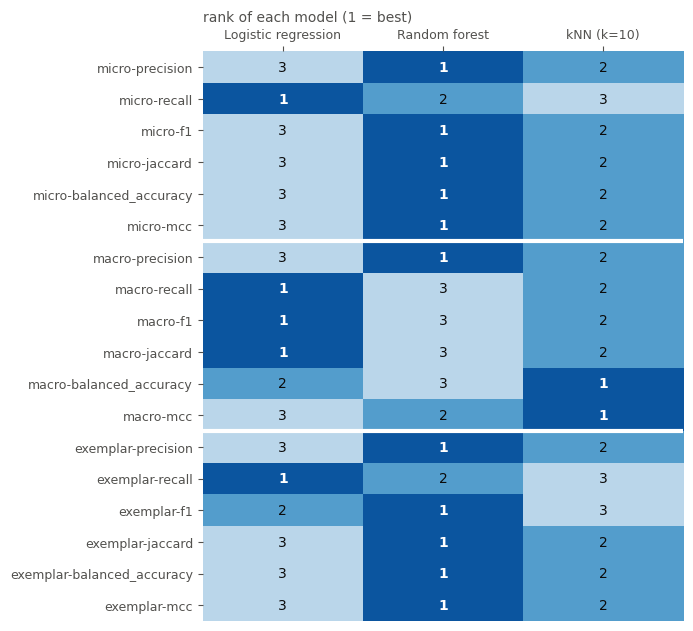

In [6]:
ranks = grid.rank(axis=1, ascending=False).astype(int)

fig, ax = plt.subplots(figsize=(6.2, 7.4))
ax.imshow(ranks.values, cmap="Blues_r", vmin=0.5, vmax=4.0, aspect="auto")
ax.set_xticks(range(ranks.shape[1]))
ax.set_xticklabels(ranks.columns, fontsize=9)
ax.set_yticks(range(ranks.shape[0]))
ax.set_yticklabels(ranks.index, fontsize=9)
ax.xaxis.tick_top()
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
for i in range(ranks.shape[0]):
    for j in range(ranks.shape[1]):
        r = ranks.iat[i, j]
        ax.text(j, i, str(r), ha="center", va="center", fontsize=10,
                color="white" if r == 1 else INK, fontweight="bold" if r == 1 else "normal")
for k in (6, 12):                        # separate the three operators
    ax.axhline(k - 0.5, color="white", linewidth=3)
ax.set_title("rank of each model (1 = best)", loc="left", fontsize=10, color=INK2)
plt.show()

In [7]:
first = ranks.eq(1).sum()
last = ranks.eq(3).sum()
pd.DataFrame({"ranked first in": first, "ranked last in": last})

,ranked first in,ranked last in
Logistic regression,5,11
Random forest,11,4
kNN (k=10),2,3


The ranking is not stable. Under micro- and exemplar-$F_1$ the random forest is first; under
macro-$F_1$ and macro-recall it is last; macro-MCC prefers a third model. None of the 18
combinations is wrong, they answer different questions:

| Operator | Question it answers |
|---|---|
| micro | How well does the model do over all label decisions, dominated by frequent labels? |
| macro | How well does it do on a typical *label*, rare labels counting as much as common ones? |
| exemplar | How well does it do on a typical *example*? |

## Is the difference larger than the noise?

Five folds give five values per model. The spread across folds shows how much of a
difference could be sampling noise.

In [8]:
rows = []
for name, ims in folds.items():
    per_fold = [im.compute("f1", "macro") for im in ims]
    rows.append(dict(model=name,
                     pooled=fold_aggregate(ims, "f1", "macro", pooling="pooled"),
                     averaged=fold_aggregate(ims, "f1", "macro", pooling="averaged"),
                     sd_across_folds=np.std(per_fold, ddof=1)))
pd.DataFrame(rows).set_index("model").round(4)

,pooled,averaged,sd_across_folds
model,,,
Logistic regression,0.3898,0.3901,0.0240
Random forest,0.3623,0.3611,0.0213
kNN (k=10),0.3832,0.3823,0.0148


The macro-$F_1$ gap between the logistic regression and the forest (about 0.03) is of the
same size as the standard deviation across folds (about 0.02). So the flip above is not
evidence that one model is better: it shows what each operator rewards. The forest is more
precise on the frequent labels, which micro and exemplar averages weight heavily; the logistic
regression has the higher macro-recall, that is, it finds a larger share of the positives on
the average label, which is what a macro average rewards.

`pooled` and `averaged` are close here because the folds are large. They differ in general,
because macro-$F_1$ is not linear in the counts: averaging per-fold scores is not the same as
scoring the pooled predictions, and the gap grows with small folds and rare labels.

## What does `diagnose` say?

In [9]:
im_all = IndicatorMatrix(
    np.vstack([im.Y for im in folds["kNN (k=10)"]]),
    np.vstack([im.P for im in folds["kNN (k=10)"]]),
    task="multilabel")
for f in diagnose(im_all, ["precision", "f1", "mcc"]):
    print(f)

[warning] outside_hull: micro-mcc = 0.5066 lies outside the range of the per-class values [0.1020, 0.4459], so it is not a weighted average of them. 'mcc' is not aggregation-decomposable.
[warning] undefined_entries: macro-precision has 2 of 14 undefined entries; the reported value is 0.6710 under the exclusion convention and 0.5751 under substitution of zero (difference 0.0959).
[warning] undefined_entries: exemplar-precision has 52 of 2417 undefined entries; the reported value is 0.7219 under the exclusion convention and 0.7063 under substitution of zero (difference 0.0155).
[warning] undefined_entries: macro-mcc has 2 of 14 undefined entries; the reported value is 0.2621 under the exclusion convention and 0.2247 under substitution of zero (difference 0.0374).
[warning] undefined_entries: exemplar-mcc has 52 of 2417 undefined entries; the reported value is 0.5133 under the exclusion convention and 0.5023 under substitution of zero (difference 0.0110).


Two things to notice on real data. The micro-MCC of the kNN model lies *outside* the
range of its 14 per-label MCC values, so it cannot be read as a weighted average of them (see
notebook 02). And two labels are never predicted, so macro-precision depends on the convention
for $0/0$: 0.671 with `exclude`, 0.575 with `zero`.

## What to report

- Name the operator with the measure, and decide which question matters before looking at the
  ranking: rare labels (macro), overall label decisions (micro), or per-example quality
  (exemplar).
- If different operators disagree about the best model, report the grid, not one cell.
- Use `fold_aggregate(..., pooling="pooled")` for non-linear measures; averaging per-fold
  scores biases them.

Next steps: soft labels, ordinal and cost-sensitive evaluation, and `scikit-learn` pipelines.